# Probar Loader y Segmentation

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

***Objetivo:*** El objetivo de este proyecto es desarrollar y desplegar un producto basado en datos. Cada equipo debe seleccionar un problema y un conjunto de datos asociado. A lo largo del semestre deben ir desarrollando la solución, desde la comprensión del problema de negocio y los datos, hasta el despliegue de la solución analítica. El nivel esperado de desarrollo de este producto es de un prototipo funcional. La solución debe consistir de modelos supervisados empaquetados, una API para servir las inferencias y un tablero que permita emplear el modelo a través de la API y visualizar otros datos relevantes para el usuario. Eldespliegue debe hacerse empleando contenedores Docker.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import mne
import gc
import os


In [2]:
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

DATA_DIR = project_root / "data/sleep-edfx/sleep-cassette"  # carpeta donde están tus archivos .edf
OUT_DIR = project_root / "data/epochs_por_sujeto" # carpeta donde se guardaria cada secuencia 

os.makedirs(OUT_DIR, exist_ok=True)

In [3]:
from src.data.loader import load_subject, find_subject_pairs
from src.data.segmentation import (
    extract_epochs,
    concatenate_datasets,
    class_distribution,
    INT_TO_CLASS,
    concatenate_datasets_by_split,
    trim_wake_edges
)

In [ ]:
SUJETO_PSG = "SC4012E0"
SUJETO_HYP = "SC4012EC"
PSG_PATH = project_root / f"data/sleep-edfx/sleep-cassette/{SUJETO_PSG}-PSG.edf"
HYPNO_PATH = project_root / f"data/sleep-edfx/sleep-cassette/{SUJETO_HYP}-Hypnogram.edf"

subject = load_subject(PSG_PATH, HYPNO_PATH)

print("Sujeto:", subject.subject_id)
print("Canales disponibles:", subject.raw.ch_names)
print("sfreq:", subject.raw.info["sfreq"], "Hz")
print("Duración PSG:", subject.raw.n_times / subject.raw.info["sfreq"], "s")
print("N° anotaciones:", len(subject.annotations))

In [5]:
print(f"Ejemplo {SUJETO_PSG}\n")

print("Los canales disponibles son:")
print(subject.raw.ch_names)

Ejemplo SC4012E0

Los canales disponibles son:
['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']


In [6]:
dataset = extract_epochs(
    subject.raw,
    subject.annotations,
    recording_id=subject.subject_id,
    channel_picks=["EEG Fpz-Cz"],   #<- Acá se pueden colocar mas canales, los dejo en la anterior celda
    scale_to_uv=True,               # microvoltios por defecto
)

print("X shape:", dataset.X.shape, " (n_epochs, n_channels, n_samples)")
print("y shape:", dataset.y.shape)
print("Unidad de señal:", dataset.signal_unit)
print("Sujeto/noche:", dataset.subject_code[1], "/", dataset.night)
print("Épocas descartadas:", dataset.dropped_epochs)

X shape: (2848, 1, 3000)  (n_epochs, n_channels, n_samples)
y shape: (2848,)
Unidad de señal: uV
Sujeto/noche: 1 / 2
Épocas descartadas: 2


In [7]:
i = 1000  # acá pueden cambiar el índice para alguna época

print("X[i].shape:", dataset.X[i].shape)
print("X[i][0][:6] (uV):", np.round(dataset.X[i][0][:6], 2))
print("y[i]:", dataset.y[i], "->", INT_TO_CLASS[dataset.y[i]])
print("recording_id:", dataset.recording_ids[i])
print("subject_code:", dataset.subject_codes[i])

X[i].shape: (1, 3000)
X[i][0][:6] (uV): [ -6.57  -6.38  -9.27 -10.66  -6.85  -7.32]
y[i]: 2 -> N2
recording_id: SC4012E0
subject_code: 01


{'W': 1824, 'N1': 92, 'N2': 660, 'N3': 96, 'REM': 176}


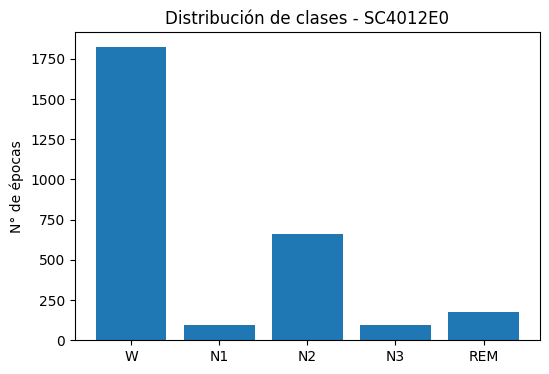

In [8]:
dist = class_distribution(dataset)
print(dist)

plt.figure(figsize=(6, 4))
plt.bar(dist.keys(), dist.values())
plt.title(f"Distribución de clases - {dataset.recording_id}")
plt.ylabel("N° de épocas")
plt.show()

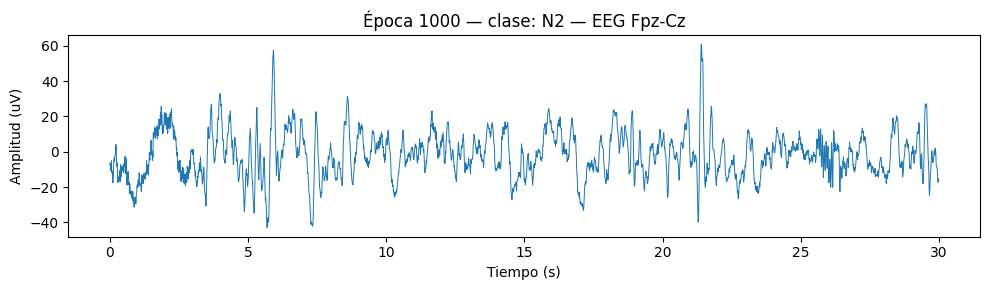

In [9]:
i = 1000
signal = dataset.X[i][0]  # canal 0
t = np.arange(len(signal)) / dataset.sfreq  # eje de tiempo en segundos

plt.figure(figsize=(10, 3))
plt.plot(t, signal, linewidth=0.7)
plt.title(f"Época {i} — clase: {INT_TO_CLASS[dataset.y[i]]} — {dataset.channel_names[0]}")
plt.xlabel("Tiempo (s)")
plt.ylabel(f"Amplitud ({dataset.signal_unit})")
plt.tight_layout()
plt.show()

## Generación de archivos npz

In [13]:
pairs = find_subject_pairs(DATA_DIR)
print(f"{len(pairs)} par(es) encontrados")

for psg_path, hypno_path in pairs:
    recording_id = os.path.basename(psg_path).split("-")[0]
    out_path = os.path.join(OUT_DIR, f"{recording_id}_epochs.npz")

    if os.path.exists(out_path):
        print(f"[skip] {recording_id} ya procesado")
        continue

    try:
        subj = load_subject(psg_path, hypno_path)
        ds = extract_epochs(
            subj.raw, subj.annotations,
            recording_id=recording_id,
            channel_picks=["EEG Fpz-Cz"],  # menos canales = menos RAM
        )

        ds = trim_wake_edges(ds, buffer_epochs=60) #<-- Si desean mantener toda la secuencia se quita esta linea
        np.savez_compressed(
            out_path,
            X=ds.X,
            y=ds.y,
            recording_ids=ds.recording_ids.astype(str),
            subject_codes=ds.subject_codes.astype(str),
            channel_names=np.array(ds.channel_names),
            sfreq=ds.sfreq,
            signal_unit=ds.signal_unit,
        )
        print(f"[ok] {recording_id}: {ds.X.shape}")

    except Exception as e:
        print(f"[error] {recording_id}: {e}")

    finally:
        # liberar todo explícitamente antes del siguiente sujeto
        del subj, ds
        gc.collect()

## Verificación de archivos generados

Estas celdas abren uno de los archivos creados en `OUT_DIR` y comprueban que el contenido tenga la estructura esperada: señales `X`, etiquetas `y`, metadatos por época, frecuencia de muestreo, canales y unidad de señal.

In [14]:
npz_files = sorted(OUT_DIR.glob("*_epochs.npz"))

print(f"Archivos .npz encontrados: {len(npz_files)}")
for path in npz_files:
    size_mb = path.stat().st_size / (1024 ** 2)
    print(f"- {path.name}: {size_mb:.2f} MB")

if not npz_files:
    raise FileNotFoundError(f"No se encontraron archivos .npz en {OUT_DIR}")

Archivos .npz encontrados: 10
- SC4001E0_epochs.npz: 4.42 MB
- SC4002E0_epochs.npz: 5.88 MB
- SC4011E0_epochs.npz: 5.37 MB
- SC4012E0_epochs.npz: 5.99 MB
- SC4021E0_epochs.npz: 4.84 MB
- SC4022E0_epochs.npz: 4.99 MB
- SC4031E0_epochs.npz: 4.63 MB
- SC4032E0_epochs.npz: 4.76 MB
- SC4041E0_epochs.npz: 6.11 MB
- SC4042E0_epochs.npz: 6.14 MB


In [15]:
npz_path = npz_files[3]
print("Archivo seleccionado:", npz_path.name)

with np.load(npz_path, allow_pickle=False) as npz:
    print("Claves guardadas:", npz.files)

    X = npz["X"]
    y = npz["y"]
    recording_ids = npz["recording_ids"]
    subject_codes = npz["subject_codes"]
    channel_names = npz["channel_names"]
    sfreq = float(npz["sfreq"])
    signal_unit = str(npz["signal_unit"])

print("\nResumen del contenido")
print("X shape:", X.shape, "(n_epochs, n_channels, n_samples)")
print("y shape:", y.shape)
print("recording_ids shape:", recording_ids.shape)
print("subject_codes shape:", subject_codes.shape)
print("channel_names:", channel_names)
print("sfreq:", sfreq, "Hz")
print("signal_unit:", signal_unit)
print("dtype X:", X.dtype)
print("dtype y:", y.dtype)

assert X.ndim == 3, "X debe tener forma (n_epochs, n_channels, n_samples)"
assert y.ndim == 1, "y debe ser un vector de etiquetas"
assert X.shape[0] == y.shape[0], "X e y deben tener el mismo número de épocas"
assert recording_ids.shape[0] == X.shape[0], "Debe existir un recording_id por época"
assert subject_codes.shape[0] == X.shape[0], "Debe existir un subject_code por época"
assert X.shape[1] == len(channel_names), "El número de canales debe coincidir con channel_names"
assert X.shape[2] == int(round(30 * sfreq)), "Cada época debe tener 30 segundos de muestras"
assert np.isfinite(X).all(), "X contiene valores NaN o infinitos"

print("\nEl archivo .npz tiene la estructura esperada.")

Archivo seleccionado: SC4012E0_epochs.npz
Claves guardadas: ['X', 'y', 'recording_ids', 'subject_codes', 'channel_names', 'sfreq', 'signal_unit']

Resumen del contenido
X shape: (1186, 1, 3000) (n_epochs, n_channels, n_samples)
y shape: (1186,)
recording_ids shape: (1186,)
subject_codes shape: (1186,)
channel_names: ['EEG Fpz-Cz']
sfreq: 100.0 Hz
signal_unit: uV
dtype X: float32
dtype y: int64

El archivo .npz tiene la estructura esperada.


Primera época
recording_id: SC4012E0
subject_code: 01
clase: 4 -> REM
primeras 10 muestras: [13.53 10.83 12.22 13.34 11.39  6.83  2.55  4.04 -1.36 -2.48]
mín / media / máx: [-73.93  -1.54  46.28]


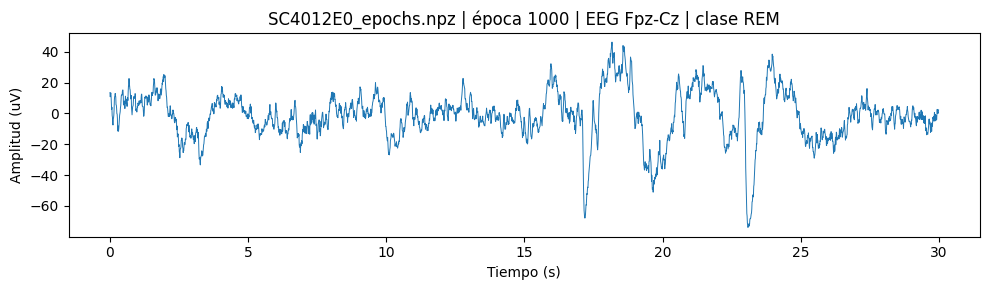

In [39]:
idx = 1000
signal = X[idx, 0]
t = np.arange(signal.shape[0]) / sfreq
label = INT_TO_CLASS[int(y[idx])]

print("Primera época")
print("recording_id:", recording_ids[idx])
print("subject_code:", subject_codes[idx])
print("clase:", int(y[idx]), "->", label)
print("primeras 10 muestras:", np.round(signal[:10], 2))
print("mín / media / máx:", np.round([signal.min(), signal.mean(), signal.max()], 2))

plt.figure(figsize=(10, 3))
plt.plot(t, signal, linewidth=0.7)
plt.title(f"{npz_path.name} | época {idx} | {channel_names[0]} | clase {label}")
plt.xlabel("Tiempo (s)")
plt.ylabel(f"Amplitud ({signal_unit})")
plt.tight_layout()
plt.show()

In [17]:
npz_files

## Ejemplo usando concatenate_datasets

`concatenate_datasets` recibe una lista de objetos `EpochDataset`. Como los archivos `.npz` guardan los arreglos y metadatos principales, primero reconstruimos un `EpochDataset` por archivo y luego concatenamos varios en un único dataset.

In [18]:
from src.data.segmentation import EpochDataset, parse_recording_id


def load_epoch_dataset_npz(path):
    """Reconstruye un EpochDataset desde uno de los .npz guardados."""
    with np.load(path, allow_pickle=False) as npz:
        X = npz["X"]
        y = npz["y"]
        recording_ids = npz["recording_ids"]
        subject_codes = npz["subject_codes"]
        channel_names = npz["channel_names"].astype(str).tolist()
        sfreq = float(npz["sfreq"])
        signal_unit = str(npz["signal_unit"].item())

    recording_id = str(recording_ids[0])
    subject_code, night = parse_recording_id(recording_id)

    return EpochDataset(
        recording_id=recording_id,
        subject_code=subject_code,
        night=night,
        X=X,
        y=y,
        recording_ids=recording_ids.astype(str),
        subject_codes=subject_codes.astype(str),
        channel_names=channel_names,
        sfreq=sfreq,
        signal_unit=signal_unit,
        dropped_epochs=0,  # este metadato no quedó guardado en el .npz
    )


npz_files = sorted(OUT_DIR.glob("*_epochs.npz"))
selected_files = npz_files[:2]  # cambia este slice si quieres concatenar más sujetos/noches

datasets_from_npz = [load_epoch_dataset_npz(path) for path in selected_files]
combined_dataset = concatenate_datasets(datasets_from_npz)

print("Archivos concatenados:")
for path, ds in zip(selected_files, datasets_from_npz):
    print(f"- {path.name}: X={ds.X.shape}, y={ds.y.shape}, sujeto={ds.subject_code}, noche={ds.night}")

print("\nDataset combinado")
print("recording_id:", combined_dataset.recording_id)
print("X shape:", combined_dataset.X.shape)
print("y shape:", combined_dataset.y.shape)
print("recording_ids únicos:", np.unique(combined_dataset.recording_ids))
print("subject_codes únicos:", np.unique(combined_dataset.subject_codes))
print("Distribución de clases:", class_distribution(combined_dataset))

expected_epochs = sum(ds.X.shape[0] for ds in datasets_from_npz)
assert combined_dataset.X.shape[0] == expected_epochs
assert combined_dataset.y.shape[0] == expected_epochs

print("\nDatasets concatenados correctamente.")

Archivos concatenados:
- SC4001E0_epochs.npz: X=(841, 1, 3000), y=(841,), sujeto=00, noche=1
- SC4002E0_epochs.npz: X=(1127, 1, 3000), y=(1127,), sujeto=00, noche=2

Dataset combinado
recording_id: SC4001E0+SC4002E0
X shape: (1968, 1, 3000)
y shape: (1968,)
recording_ids únicos: ['SC4001E0' 'SC4002E0']
subject_codes únicos: ['00']
Distribución de clases: {'W': 371, 'N1': 117, 'N2': 623, 'N3': 517, 'REM': 340}

Datasets concatenados correctamente.


La parte importante de `concatenate_datasets` es que conserva la trazabilidad: cada época sigue sabiendo de qué grabación y de qué sujeto viene mediante recording_ids y subject_codes. Eso nos sirve después para hacer splits correctos, por ejemplo separar train/test por sujeto y evitar data leakage.

## Ejemplo usando concatenate_datasets_by_split

In [40]:
split_df = pd.read_excel(project_root / f"data/sleep-edfx/SC-subjects-split.xlsx")
split_df["subject_code"] = split_df["subject"].astype(str).str.zfill(2)

subject_to_split = dict(zip(split_df["subject_code"], split_df["split"]))

print(f"N° de sujetos mapeados: {len(subject_to_split)}")

N° de sujetos mapeados: 78


### Con todos los ejemplos

In [42]:
import glob

def load_epoch_dataset_npz(npz_path: str) -> EpochDataset:
    data = np.load(npz_path)
    recording_id = str(data["recording_ids"][0])
    subject_code = str(data["subject_codes"][0])
    return EpochDataset(
        recording_id=recording_id,
        subject_code=subject_code,
        night="unknown",  # no se guardó explícitamente en el .npz; se puede recalcular con parse_recording_id si lo necesitas
        X=data["X"],
        y=data["y"],
        recording_ids=data["recording_ids"],
        subject_codes=data["subject_codes"],
        channel_names=list(data["channel_names"]),
        sfreq=float(data["sfreq"]),
        signal_unit=str(data["signal_unit"]),
        dropped_epochs=0,  # no se guardó; no crítico para el entrenamiento
    )

npz_paths = glob.glob(str(project_root / "data/epochs_por_sujeto" / "*.npz"))
todas_las_grabaciones = [load_epoch_dataset_npz(p) for p in npz_paths]

train_ds = concatenate_datasets_by_split(todas_las_grabaciones, subject_to_split, "train")
test_ds = concatenate_datasets_by_split(todas_las_grabaciones, subject_to_split, "test")

In [43]:
type(train_ds)

src.data.segmentation.EpochDataset

In [44]:
print("Train X shape:", train_ds.X.shape, "| recording_ids:", set(train_ds.recording_ids))
print("Test X shape:", test_ds.X.shape, "| recording_ids:", set(test_ds.recording_ids))
print("\nDistribución de clases en train:", class_distribution(train_ds))
print("Distribución de clases en test:", class_distribution(test_ds))

Train X shape: (8154, 1, 3000) | recording_ids: {np.str_('SC4012E0'), np.str_('SC4021E0'), np.str_('SC4011E0'), np.str_('SC4001E0'), np.str_('SC4022E0'), np.str_('SC4002E0'), np.str_('SC4031E0'), np.str_('SC4032E0')}
Test X shape: (2435, 1, 3000) | recording_ids: {np.str_('SC4042E0'), np.str_('SC4041E0')}

Distribución de clases en train: {'W': 1219, 'N1': 702, 'N2': 3677, 'N3': 1120, 'REM': 1436}
Distribución de clases en test: {'W': 385, 'N1': 303, 'N2': 1134, 'N3': 147, 'REM': 466}


{'W': 1219, 'N1': 702, 'N2': 3677, 'N3': 1120, 'REM': 1436}


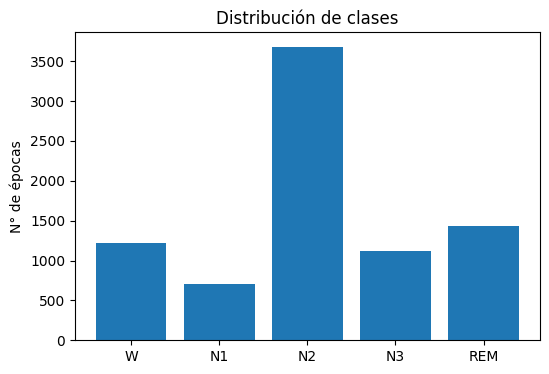

In [45]:
dist = class_distribution(train_ds)
print(dist)

plt.figure(figsize=(6, 4))
plt.bar(dist.keys(), dist.values())
plt.title(f"Distribución de clases")
plt.ylabel("N° de épocas")
plt.show()